1. Veriyi Yükleme (Import Data)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('housing.csv')


2. Veriyi İnceleme (Data Exploration)

In [2]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [5]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

3. Keşifçi Veri Analizi ve Görselleştirme (EDA)

In [6]:
df.corr(numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


<Figure size 1000x600 with 0 Axes>

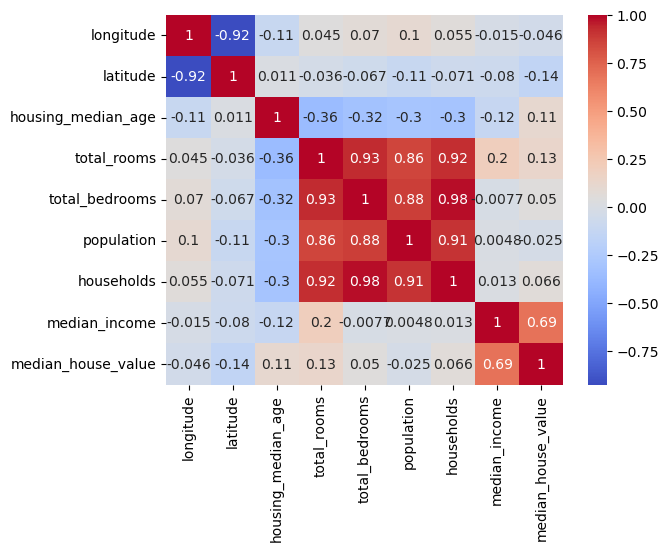

<Figure size 1000x600 with 0 Axes>

In [7]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.figure(figsize=(10,6))


Text(0.5, 1.0, 'Scatter Plot of Median Income vs Median House Value')

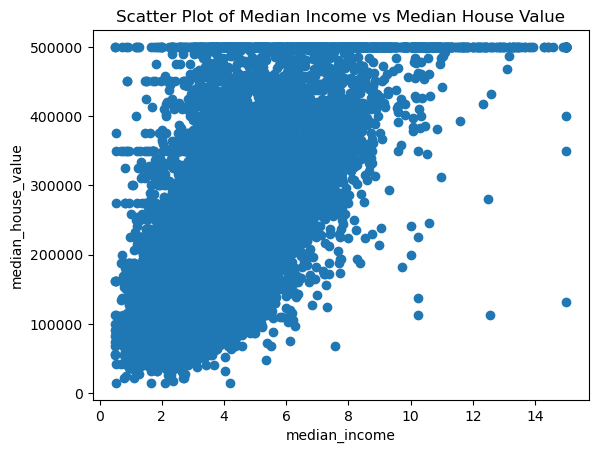

In [8]:
plt.scatter(df["median_income"], df["median_house_value"])
plt.xlabel("median_income")
plt.ylabel("median_house_value")
plt.title("Scatter Plot of Median Income vs Median House Value")

5. Kategorik Verileri Encode Etme (Encoding)

In [9]:
df["ocean_proximity"].unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [10]:
from sklearn.preprocessing import OrdinalEncoder
ordinal_encoder = OrdinalEncoder()
class_order=['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
ordinal_encoder=OrdinalEncoder(categories=[class_order])
df["ocean_proximity"]=ordinal_encoder.fit_transform(df[["ocean_proximity"]])
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0.0


In [11]:
df["ocean_proximity"].unique()

array([0., 1., 2., 3., 4.])

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  float64
dtypes: float64(10)
memory usage: 1.6 MB


In [13]:
df = df[df["median_house_value"] < 500000]

4. Train ve Test Olarak Ayırma (Train & Test Split)


In [14]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

In [15]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0.0


In [16]:
y.head()

0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((14736, 9), (4912, 9), (14736,), (4912,))

5. Eksik Verileri Temizleme veya Doldurma (Filling Missing Datas)

In [18]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        200
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [19]:
df['total_bedrooms'].fillna(df['total_bedrooms'].median(), inplace=True)

C:\Users\parsk\AppData\Local\Temp\ipykernel_9812\1590527289.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['total_bedrooms'].fillna(df['total_bedrooms'].median(), inplace=True)


In [20]:
df.isnull().sum()


longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

6. Veriyi Ölçeklendirme (Scaling)

In [21]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test) 
#burada ne yaptık: train setini fit_transform ile ölçeklendirdik, test setini ise sadece transform ile ölçeklendirdik. Çünkü test seti üzerinde fit yaparsak, modelimiz test setine aşırı uyum sağlayabilir ve gerçek performansını değerlendiremeyiz. Bu nedenle, test setini sadece transform ederek, modelimizin gerçek performansını daha doğru bir şekilde değerlendirebiliriz.


In [22]:
X_train

array([[ 0.67981458, -0.71658299,  1.88492692, ..., -0.46725937,
        -0.13660722, -0.55974582],
       [-1.25361395,  1.0391668 ,  0.28503503, ..., -0.85029977,
         0.87164091, -1.74367209],
       [ 0.59987955, -0.83270401, -0.7548947 , ..., -0.93311931,
         1.48780665, -0.55974582],
       ...,
       [ 0.64484301, -0.87915242,  1.48495395, ..., -1.12981573,
        -0.48988151, -0.55974582],
       [-1.17867486,  0.84872833, -1.87481903, ..., -0.66395579,
        -0.06743863, -0.55974582],
       [-0.82396316,  0.98807356, -1.87481903, ..., -0.15150986,
         0.50750543,  0.62418046]])

In [23]:
X_test

array([[ 0.57489986, -0.77232108,  1.32496476, ..., -0.33785384,
         0.86262168, -0.55974582],
       [-1.18866674,  0.77441088,  0.60501341, ..., -0.45949504,
         0.68776297, -0.55974582],
       [-0.42428802, -0.36821994, -0.8348893 , ..., -0.30938462,
         0.73571732, -0.55974582],
       ...,
       [ 1.21937603, -1.35757102,  1.72493773, ..., -0.46467126,
        -0.66855116,  1.80810673],
       [-0.64910529,  1.6197719 , -0.91488389, ..., -0.56560758,
        -0.51909873,  0.62418046],
       [ 0.19520847, -0.6608449 , -0.91488389, ..., -0.81665433,
        -0.24953812,  1.80810673]])

In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
linear_regression=LinearRegression()
linear_regression.fit(X_train, y_train)


LinearRegression()

In [25]:
y_pred=linear_regression.predict(X_test)


In [26]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)
print("mse: ",mse)
print("mae: ",mae)
print("rmse: ",rmse)
print("r2: ",r2)

mse:  3897616501.005277
mae:  46337.28648950661
rmse:  62430.89380271018
r2:  0.5897022103713826


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly=PolynomialFeatures(degree=2,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

linear_regression_poly=LinearRegression()
linear_regression_poly.fit(X_train_poly, y_train)





LinearRegression()

In [28]:
y_pred=linear_regression_poly.predict(X_test_poly)
score=r2_score(y_test,y_pred)
score

0.5518728976674874

In [29]:
# Pipeline ne işe yarar: aynı anda 8 9 tane degree için kullandığımız olay
# tamamen işimizi kolaylaştırmak için oluşturulmuştur
from sklearn.pipeline import Pipeline
def poly_regression(degree):
    poly_features=PolynomialFeatures(degree=degree)
    lin_reg=LinearRegression()
    scaler=StandardScaler()
    pipeline=Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
        ]
    )
    pipeline.fit(X_train,y_train)
    score=pipeline.score(X_test,y_test)
    print(score)


In [30]:
from sklearn.preprocessing import PolynomialFeatures

for i in range(1, 6):
    poly_regression(i)
    

0.5897022103713826
0.5518728976674874
-1.4077947278405043
-267.2126821658816
-59971.782709822786


mean_absolute_error: 46356.18387664371
mean_squared_error: 3896339915.2160373
r2_score: 0.5898365951492235


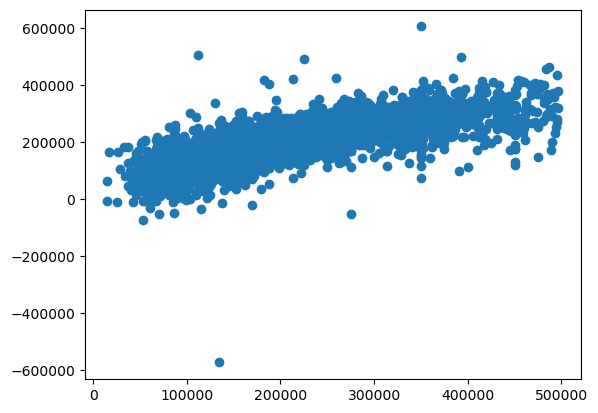

In [ ]:
#lasso cross validation
from sklearn.linear_model import LassoCV
lassoCV=LassoCV(cv=5)
lassoCV.fit(X_train_poly,y_train)
y_pred=lassoCV.predict(X_test_poly)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error:",mae)
print("mean_squared_error:",mse)
print("r2_score:",score)
plt.scatter(y_test,y_pred)
plt.show()

mean_absolute_error: 46333.27838363481
mean_squared_error: 3896048679.072462
r2_score: 0.5898672532567972


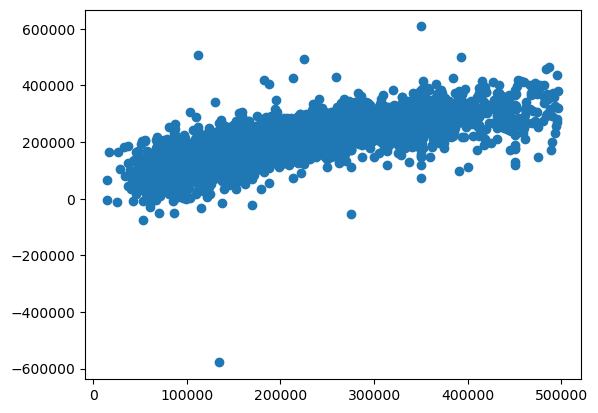

In [36]:
#ridge cross validation
from sklearn.linear_model import RidgeCV
ridgeCV=RidgeCV(cv=5)
ridgeCV.fit(X_train,y_train)
y_pred=ridgeCV.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error:",mae)
print("mean_squared_error:",mse)
print("r2_score:",score)
plt.scatter(y_test,y_pred)
plt.show()

mean_absolute_error: 77569.88894196699
mean_squared_error: 9344721895.458046
r2_score: 0.01629143415939449


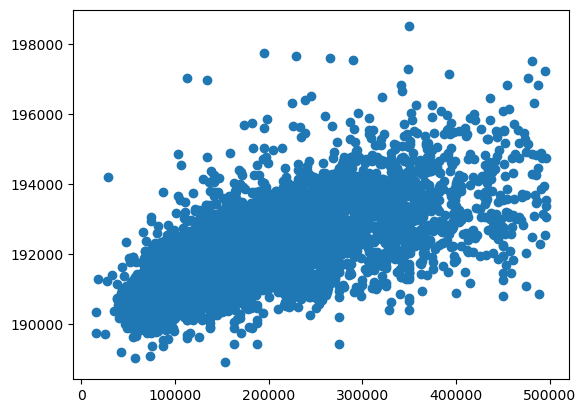

In [34]:
from sklearn.linear_model import ElasticNetCV
elasticNetCV=ElasticNetCV(cv=5)
elasticNetCV.fit(X_train,y_train)
y_pred=elasticNetCV.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error:",mae)
print("mean_squared_error:",mse)
print("r2_score:",score)
plt.scatter(y_test,y_pred)
plt.show()

In [39]:
from sklearn.ensemble import RandomForestRegressor
random_forest=RandomForestRegressor()
random_forest.fit(X_train,y_train)
y_pred=random_forest.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
score=r2_score(y_test,y_pred)
print("mean_absolute_error:",mae)
print("mean_squared_error:",mse)
print("r2_score:",score)


mean_absolute_error: 30817.335637214986
mean_squared_error: 2098395075.4493754
r2_score: 0.7791042651316791
